In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pokemon = pd.read_csv("pokemon.csv")
pokemon.head()

,#,Name,Type 1,Type 2,Total,HP,Attack,Defense,Sp. Atk,Sp. Def,Speed,Generation,Legendary
0,1,Bulbasaur,Grass,Poison,318,45,49,49,65,65,45,1,False
1,2,Ivysaur,Grass,Poison,405,60,62,63,80,80,60,1,False
2,3,Venusaur,Grass,Poison,525,80,82,83,100,100,80,1,False
3,3,VenusaurMega Venusaur,Grass,Poison,625,80,100,123,122,120,80,1,False
4,4,Charmander,Fire,NaN,309,39,52,43,60,50,65,1,False


## Provenance & scope
Q1. Where did this data come from — who collected it, how, and why?

Q1. The data comes from the pokemon.csv file published as a GitHub Gist by armgilles. As far as I can tell, it matches the widely shared "Pokemon with stats" table, which was compiled by scraping pokemondb.net, a fan-run database. The stats themselves were designed by Game Freak for the Pokémon games, so the data is a record of design decisions rather than measurements of anything in the world. It was compiled for hobby use and for teaching data analysis. I have not confirmed the exact scrape date or method, so this provenance is my best understanding.

Q2. What does one row represent?

Q2. One row is one Pokémon form. Most rows are a single species, but alternate forms (Mega Evolutions, Primal forms, Formes such as Deoxys or Hoopa Unbound) get their own row and share the same # (National Pokédex number) as the base species.

Q3. How big is it, and what time period / population does it cover?

Q3. The data has 800 rows and 13 columns. It covers Generations 1 to 6, which are the games from Red/Green (1996) to X/Y and Omega Ruby/Alpha Sapphire (2013–2014). There are 721 distinct species plus 79 alternate forms. It is a complete list for those generations, so it is a census of that population and not a sample.

Q4. What could this data plausibly generalise to — and what tempting question can it not answer?

Q4. The data generalises only to Pokémon from Generations 1–6 as they were designed in those games. It cannot speak to Generation 7 onward, regional forms, or later stat changes. A tempting question it cannot answer is which Pokémon is the strongest in battle. Base stats leave out moves, abilities, type matchups, items and usage rates, so a high Total does not establish battle strength. It also cannot explain why the designers chose particular values.

I predict that there will be no missing values.

In [2]:
pokemon.info()
pokemon.isna().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 13 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   #           800 non-null    int64 
 1   Name        800 non-null    object
 2   Type 1      800 non-null    object
 3   Type 2      414 non-null    object
 4   Total       800 non-null    int64 
 5   HP          800 non-null    int64 
 6   Attack      800 non-null    int64 
 7   Defense     800 non-null    int64 
 8   Sp. Atk     800 non-null    int64 
 9   Sp. Def     800 non-null    int64 
 10  Speed       800 non-null    int64 
 11  Generation  800 non-null    int64 
 12  Legendary   800 non-null    bool  
dtypes: bool(1), int64(9), object(3)
memory usage: 75.9+ KB


#               0
Name            0
Type 1          0
Type 2        386
Total           0
HP              0
Attack          0
Defense         0
Sp. Atk         0
Sp. Def         0
Speed           0
Generation      0
Legendary       0
dtype: int64

## Structure & quality
Q5. What are the important variables, and what type is each?

Q5. # is the National Pokédex number. It is stored as int64 but is an identifier and should not be treated as a quantity. Name is a string label. Type 1 is nominal categorical (18 types). Type 2 is nominal categorical and blank for single-type Pokémon. HP, Attack, Defense, Sp. Atk, Sp. Def and Speed are discrete integers. Total is a discrete integer derived as the sum of the six stats. Generation is ordinal (1–6), stored as an integer. Legendary is boolean. The most important variables for analysis are Total, the six stats, Type 1, Type 2, Generation and Legendary.

Q6. What's missing — and does it have a pattern? (Type 2: 386 blank of 800)

Q6. Only Type 2 has missing values: 386 of 800 rows (48%). My prediction of no missing values was wrong. The pattern is structural. A blank Type 2 means the Pokémon has only one type, so the value is not unknown. At the species level, 371 of 721 species are single-type and 350 are dual-type. These blanks should be recoded as "None" and should not be imputed.

In [3]:
print(pokemon.duplicated().sum())
print(pokemon["Name"].duplicated().sum())
print(pokemon["#"].duplicated().sum())
pokemon[pokemon["#"].duplicated(keep=False)].head(20)

0
0
79


,#,Name,Type 1,Type 2,Total,HP,Attack,Defense,Sp. Atk,Sp. Def,Speed,Generation,Legendary
2,3,Venusaur,Grass,Poison,525,80,82,83,100,100,80,1,False
3,3,VenusaurMega Venusaur,Grass,Poison,625,80,100,123,122,120,80,1,False
6,6,Charizard,Fire,Flying,534,78,84,78,109,85,100,1,False
7,6,CharizardMega Charizard X,Fire,Dragon,634,78,130,111,130,85,100,1,False
8,6,CharizardMega Charizard Y,Fire,Flying,634,78,104,78,159,115,100,1,False
11,9,Blastoise,Water,NaN,530,79,83,100,85,105,78,1,False
12,9,BlastoiseMega Blastoise,Water,NaN,630,79,103,120,135,115,78,1,False
18,15,Beedrill,Bug,Poison,395,65,90,40,45,80,75,1,False
19,15,BeedrillMega Beedrill,Bug,Poison,495,65,150,40,15,80,145,1,False
22,18,Pidgeot,Normal,Flying,479,83,80,75,70,70,101,1,False


In [4]:
stats = ["HP", "Attack", "Defense", "Sp. Atk", "Sp. Def", "Speed"]
print((pokemon[stats].sum(axis=1) != pokemon["Total"]).sum())
pokemon[stats + ["Total"]].describe()

0


,HP,Attack,Defense,Sp. Atk,Sp. Def,Speed,Total
count,800.000000,800.000000,800.000000,800.000000,800.000000,800.000000,800.00000
mean,69.258750,79.001250,73.842500,72.820000,71.902500,68.277500,435.10250
std,25.534669,32.457366,31.183501,32.722294,27.828916,29.060474,119.96304
min,1.000000,5.000000,5.000000,10.000000,20.000000,5.000000,180.00000
25%,50.000000,55.000000,50.000000,49.750000,50.000000,45.000000,330.00000
50%,65.000000,75.000000,70.000000,65.000000,70.000000,65.000000,450.00000
75%,80.000000,100.000000,90.000000,95.000000,90.000000,90.000000,515.00000
max,255.000000,190.000000,230.000000,194.000000,230.000000,180.000000,780.00000


Q7. Are there duplicates, impossible values, or suspicious encodings?

Q7. There are no fully duplicated rows and no duplicated names. The # column has 79 repeated values, all of them alternate forms of an existing species (e.g. VenusaurMega Venusaur). These are valid rows, but they would double-count species if left in.

There are no impossible values. Total equals the sum of the six stats in all 800 rows. The minimum HP of 1 is Shedinja, which has 1 HP by design. Maximums such as HP 255 and Defense 230 are real game values and within the game's 1–255 range.

There are suspicious encodings. Alternate-form names are concatenated with the base name (e.g. "CharizardMega Charizard X"), which looks like a scraping artefact. Column names contain spaces and full stops ("Sp. Atk", "Type 1") and one is called "#", which makes them harder to work with in code. NaN in Type 2 stands for "no second type" and does not mean the value is missing.

Q8. What variables did I create or transform, and why?

Q8. I created three things. alt_form is a boolean that is True when a row's # has already appeared, and it flags the 79 alternate forms. It assumes the base form is always listed before its alternates, which holds for the Mega rows I checked. species is a copy of the data without the alternate forms (721 rows, one per species), so that Megas and Formes do not give some species extra weight in distributions and comparisons. dual_type is a boolean that is True when Type 2 is present, which turns the structural missingness into a usable variable.

In [5]:
pokemon["alt_form"] = pokemon["#"].duplicated(keep="first")
print(pokemon["alt_form"].sum())
pokemon[pokemon["alt_form"]]["Name"].tolist()

79


['VenusaurMega Venusaur',
 'CharizardMega Charizard X',
 'CharizardMega Charizard Y',
 'BlastoiseMega Blastoise',
 'BeedrillMega Beedrill',
 'PidgeotMega Pidgeot',
 'AlakazamMega Alakazam',
 'SlowbroMega Slowbro',
 'GengarMega Gengar',
 'KangaskhanMega Kangaskhan',
 'PinsirMega Pinsir',
 'GyaradosMega Gyarados',
 'AerodactylMega Aerodactyl',
 'MewtwoMega Mewtwo X',
 'MewtwoMega Mewtwo Y',
 'AmpharosMega Ampharos',
 'SteelixMega Steelix',
 'ScizorMega Scizor',
 'HeracrossMega Heracross',
 'HoundoomMega Houndoom',
 'TyranitarMega Tyranitar',
 'SceptileMega Sceptile',
 'BlazikenMega Blaziken',
 'SwampertMega Swampert',
 'GardevoirMega Gardevoir',
 'SableyeMega Sableye',
 'MawileMega Mawile',
 'AggronMega Aggron',
 'MedichamMega Medicham',
 'ManectricMega Manectric',
 'SharpedoMega Sharpedo',
 'CameruptMega Camerupt',
 'AltariaMega Altaria',
 'BanetteMega Banette',
 'AbsolMega Absol',
 'GlalieMega Glalie',
 'SalamenceMega Salamence',
 'MetagrossMega Metagross',
 'LatiasMega Latias',
 'Lati

In [6]:
pokemon["dual_type"] = pokemon["Type 2"].notna()
species = pokemon[~pokemon["alt_form"]].copy()
print(len(species))
species["dual_type"].value_counts()

721


dual_type
False    371
True     350
Name: count, dtype: int64

## Distributions & relationships

Q9. What does each key variable look like — shape, centre, spread, outliers?

Q9. At the species level (n = 721), Total ranges from 180 to 720 with a mean of about 418. The distribution is multimodal. There is a large cluster near 300, another near 500, a smaller group near 600, and a small group near 680. My interpretation is that these line up with unevolved Pokémon, fully evolved Pokémon, and legendary or pseudo-legendary Pokémon. Evolution stage is not in the data, so I cannot confirm this here.

Across all 800 rows, every individual stat has a mean above its median (e.g. HP mean 69 vs median 65, Sp. Atk mean 73 vs median 65), which indicates right skew. The spread is similar across stats, with standard deviations of about 26–33. The high outliers are real designs and should not be removed: HP 255 (Blissey), Defense and Sp. Def 230 (Shuckle), Speed 180 (Deoxys Speed Forme).

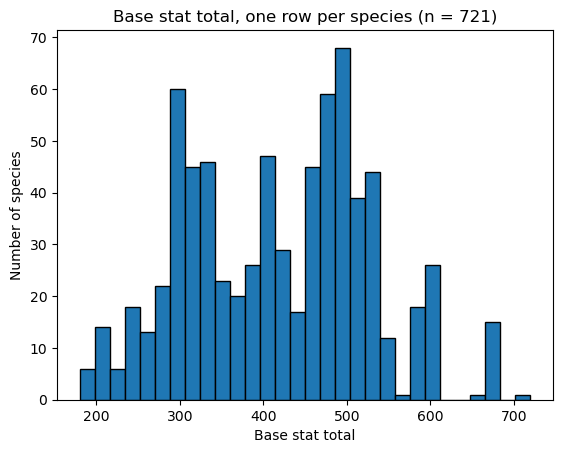

In [8]:
plt.hist(species["Total"], bins=30, edgecolor="black")
plt.xlabel("Base stat total")
plt.ylabel("Number of species")
plt.title("Base stat total, one row per species (n = 721)")
plt.show()

Q10. What are the two or three most important relationships in the data, shown and interpreted?

Q10. First, dual-type species have higher Totals than single-type species. The median is 452.5 against 405 and the mean is 432.6 against 404.1, with almost identical spread (standard deviation about 109 in both groups).

Second, Legendary status has the largest association with Total. Legendary means are about 615–624, against 393–417 for non-legendaries.

Third, the dual-type gap does not come from legendaries alone. Legendaries are more often dual-type (27 of 46, 59%) than non-legendaries (323 of 675, 48%). The gap still holds among non-legendaries (median 430 against 405, mean 416.6 against 392.7) and among legendaries (median 600 against 580). A likely confounder is evolution stage, since evolved Pokémon may gain a second type more often, but the data cannot test this.

Total being the sum of the six stats is true by construction, so it is not a finding.

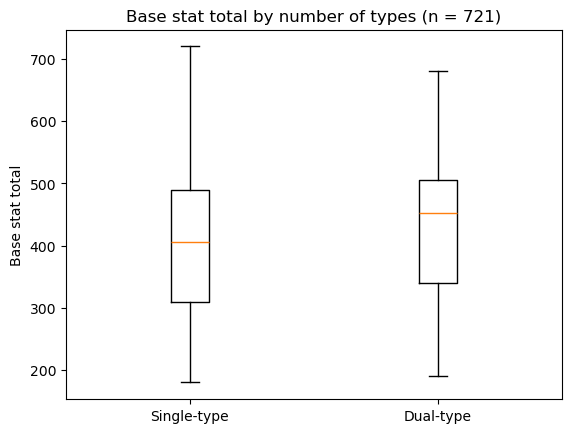

,count,mean,std,min,25%,50%,75%,max
dual_type,,,,,,,,
False,371.0,404.115903,108.905588,180.0,310.0,405.0,490.0,720.0
True,350.0,432.605714,108.707826,190.0,340.0,452.5,505.0,680.0


In [9]:
single = species.loc[~species["dual_type"], "Total"]
dual = species.loc[species["dual_type"], "Total"]
plt.boxplot([single, dual], tick_labels=["Single-type", "Dual-type"])
plt.ylabel("Base stat total")
plt.title("Base stat total by number of types (n = 721)")
plt.show()
species.groupby("dual_type")["Total"].describe()

In [10]:
print(pd.crosstab(species["Legendary"], species["dual_type"]))
species.groupby(["Legendary", "dual_type"])["Total"].agg(["count", "mean", "median"])

dual_type  False  True 
Legendary              
False        352    323
True          19     27


count        mean  median
Legendary dual_type                           
False     False        352  392.718750   405.0
          True         323  416.631579   430.0
True      False         19  615.263158   580.0
          True          27  623.703704   600.0

Q11. What's surprising here — what didn't I expect to find?

Q11. I did not expect Type 2 to be blank for nearly half the rows, since I predicted no missing values. I did not expect alternate forms to share a Pokédex number, which means the 800 rows hold only 721 species. The concatenated Mega names were also unexpected. The Total distribution has distinct clusters and gaps where I expected a single peak. I also did not expect dual-type species to score consistently higher than single-type species, even after separating out legendaries.

## Readiness

Q12. If I wanted to run an analysis tomorrow, what would I still have to do to this data?

Q12. I would rename the columns to snake_case (e.g. sp_atk, type_2, dex_no). I would recode the blank Type 2 values as "None" and store Type 1, Type 2 and Generation as categorical types, with Generation ordered. I would clean the Name column by splitting the base name from the form label. I would choose explicitly between species-level and form-level analysis depending on the question. I would check that the base form comes first for every repeated #. If evolution stage matters to the analysis, I would join it from an outside source.

Q13. What analyses is this dataset ready to support?

Q13. The dataset is ready for descriptive comparisons of stats by type, generation and Legendary status, and for correlations between the six stats. It also supports clustering of stat profiles (e.g. physical against special attackers) and simple classification, such as predicting Legendary status from stats. Because it is a complete population, the group differences are exact descriptions of these generations. Significance tests have limited meaning here.

## My questions

Q14. Has the base stat total of non-legendary species increased from Generation 1 to Generation 6?

In [11]:
nonleg = species[~species["Legendary"]]
nonleg.groupby("Generation")["Total"].agg(["count", "mean", "median"])

,count,mean,median
Generation,,,
1,147,401.693878,405.0
2,95,394.926316,410.0
3,125,384.944000,400.0
4,96,424.229167,453.0
5,146,412.520548,420.0
6,66,411.666667,417.0


Q14 answer. The data shows no steady increase. Mean Total for non-legendary species fell from Generation 1 (401.7) to Generation 2 (394.9) and Generation 3 (384.9), rose sharply in Generation 4 (424.2), then fell slightly in Generations 5 (412.5) and 6 (411.7). The medians follow a similar pattern, with the highest value in Generation 4 (453). Taken as groups, Generations 4–6 average about 416 against about 394 for Generations 1–3, a difference of roughly 22 points. That difference is small next to the spread within each generation (standard deviation about 109).

My best explanation for the Generation 4 rise is that it added many new final evolutions of older species (e.g. Magmortar, Electivire, Rhyperior, Togekiss). New evolutions would add high-Total species without adding their low-Total earlier stages. This is an inference, because the data has no evolution stage column. Generation 6 also has only 66 non-legendary species, so its average is less stable than the others.